In [25]:
import re
from pathlib import Path
import pandas as pd
import json
import subprocess
import numpy as np
import seaborn as sns
from io import BytesIO

from matplotlib.colors import LinearSegmentedColormap, Normalize
from matplotlib.cm import ScalarMappable
import matplotlib.pyplot as plt
from matplotlib.collections import PolyCollection
from matplotlib.offsetbox import AnnotationBbox, OffsetImage
from copy import deepcopy
import textwrap
from PIL import Image
import matplotlib.image as mpimg
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib.gridspec import GridSpec
from pypdf import PageObject, Transformation, PdfReader, PdfWriter
from IPython.display import Image as NotebookImage, display

In [26]:
cmap_red = LinearSegmentedColormap.from_list(
    "cmap_red",
    [
        (0.0, "#ffffff"),  # 0%: white
        (0.5, "#ffb7b7"),  # 50%: light red
        (0.99, "#ff5959"),  # 99%: dark red
        (1.0, "#ff0000"),  # 100%: red
    ],
)

cmap_blue = LinearSegmentedColormap.from_list(
    "cmap_blue",
    [
        (0.0, "#ffffff"),  # 0%: white
        (0.5, "#b7dcff"),  # 50%: light blue
        (0.9999, "#59a7ff"),  # 99%: dark blue
        (1.0, "#0074e9"),  # 100%: blue
    ],
)

project_dir = Path(r"C:\Users\evan\Desktop\Personal Projects\Pokemon Stat Optimize")
sprite_dir = project_dir / "images" / "sprites"

report_figures = []

In [27]:
stat_names = {"hp": "hp", "atk": "atk", "def": "def", "spa": "spa", "spd": "spd", "spe": "spe"}

def parse_showdown_set(block):
    lines = [line.strip() for line in block.splitlines() if line.strip()]
    pokemon_text, separator, item = lines[0].partition(" @ ")
    pokemon_text = re.sub(r"\s+\([MF]\)$", "", pokemon_text.strip())
    species_match = re.search(r"\(([^()]+)\)$", pokemon_text)
    pokemon = {"name": species_match.group(1).strip() if species_match else pokemon_text,
               "level": 50, "evs": {}, "moves": []}
    if separator:
        pokemon["item"] = item.strip()

    for line in lines[1:]:
        if line.startswith("- "):
            pokemon["moves"].append(line[2:].strip())
        elif line.lower().startswith("ability:"):
            pokemon["ability"] = line.split(":", 1)[1].strip()
        elif line.lower().startswith("level:"):
            pokemon["level"] = int(line.split(":", 1)[1].strip())
        elif line.lower().startswith("evs:"):
            for entry in line.split(":", 1)[1].split("/"):
                amount, stat = entry.strip().split(maxsplit=1)
                pokemon["evs"][stat_names[stat.lower()]] = int(amount)
        elif line.lower().endswith(" nature"):
            pokemon["nature"] = line[:-len(" nature")].strip()
    return pokemon

def read_showdown_team(path):
    text = path.read_text(encoding="utf-8").strip()
    return [parse_showdown_set(block) for block in re.split(r"\r?\n\s*\r?\n", text) if block.strip()]

attackers = read_showdown_team(project_dir / "attackers.txt")
defenders = read_showdown_team(project_dir / "defenders.txt")

print(attackers)
print(defenders)


[{'name': 'Arcanine-Hisui', 'level': 50, 'evs': {'hp': 2, 'atk': 32, 'spe': 32}, 'moves': ['Head Smash', 'Flare Blitz', 'Extreme Speed', 'Protect'], 'item': 'Focus Sash', 'ability': 'Rock Head', 'nature': 'Jolly'}]
[{'name': 'Kommo-o', 'level': 50, 'evs': {'def': 8, 'spa': 29, 'spe': 29}, 'moves': ['Clanging Scales', 'Aura Sphere', 'Clangorous Soul', 'Protect'], 'item': 'Leftovers', 'ability': 'Soundproof', 'nature': 'Modest'}]


In [28]:
def sprite_path_for(name):
    slug = re.sub(r"[^a-z0-9]+", "-", name.casefold()).strip("-")
    candidates = [sprite_dir / f"{slug}.png"]
    if slug.endswith("-f"):
        candidates.append(sprite_dir / f"{slug[:-2]}-female.png")
    for path in candidates:
        if path.is_file():
            return path
    searched = ", ".join(str(path) for path in candidates)
    raise FileNotFoundError(f"No sprite found for {name!r}; checked: {searched}")

In [29]:
matchup_requests = [
    {"attacker": {key: value for key, value in attacker.items() if key != "moves"},
     "defender": {key: value for key, value in defender.items() if key != "moves"},
     "move": move,
     "field": {"gameType": "Doubles"}}
    for attacker in attackers
    for defender in defenders
    for move in attacker["moves"]
]

for request in matchup_requests:
    participants = {
        request["attacker"]["name"],
        request["defender"]["name"],
    }

    field = request["field"]

    if "Indeedee-F" in participants:
        field["terrain"] = "Psychic"

    if "Mr. Rime" in participants:
        field["terrain"] = "Psychic"

    if "Froslass-Mega" in participants:
        field["weather"] = "Snow"
    elif "Pelipper" in participants:
        field["weather"] = "Rain"

    if field:
        request["field"] = field

matchup_requests

[{'attacker': {'name': 'Arcanine-Hisui',
   'level': 50,
   'evs': {'hp': 2, 'atk': 32, 'spe': 32},
   'item': 'Focus Sash',
   'ability': 'Rock Head',
   'nature': 'Jolly'},
  'defender': {'name': 'Kommo-o',
   'level': 50,
   'evs': {'def': 8, 'spa': 29, 'spe': 29},
   'item': 'Leftovers',
   'ability': 'Soundproof',
   'nature': 'Modest'},
  'move': 'Head Smash',
  'field': {'gameType': 'Doubles'}},
 {'attacker': {'name': 'Arcanine-Hisui',
   'level': 50,
   'evs': {'hp': 2, 'atk': 32, 'spe': 32},
   'item': 'Focus Sash',
   'ability': 'Rock Head',
   'nature': 'Jolly'},
  'defender': {'name': 'Kommo-o',
   'level': 50,
   'evs': {'def': 8, 'spa': 29, 'spe': 29},
   'item': 'Leftovers',
   'ability': 'Soundproof',
   'nature': 'Modest'},
  'move': 'Flare Blitz',
  'field': {'gameType': 'Doubles'}},
 {'attacker': {'name': 'Arcanine-Hisui',
   'level': 50,
   'evs': {'hp': 2, 'atk': 32, 'spe': 32},
   'item': 'Focus Sash',
   'ability': 'Rock Head',
   'nature': 'Jolly'},
  'defender'

In [30]:
try:
    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": matchup_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

move_results = json.loads(result.stdout)
move_results

[{'attacker': 'Arcanine-Hisui',
  'defender': 'Kommo-o',
  'move': 'Head Smash',
  'category': 'Physical',
  'damage': [46, 47, 48, 48, 48, 49, 50, 51, 51, 51, 52, 53, 53, 54, 54, 55],
  'maxDamage': 55,
  'minDamage': 46,
  'description': '32 Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 Def Kommo-o: 46-55 (30.6 - 36.6%) -- guaranteed 4HKO after Leftovers recovery',
  'attackerStats': {'hp': 172,
   'atk': 167,
   'def': 100,
   'spa': 103,
   'spd': 100,
   'spe': 156},
  'defenderStats': {'hp': 150,
   'atk': 117,
   'def': 153,
   'spa': 163,
   'spd': 125,
   'spe': 134}},
 {'attacker': 'Arcanine-Hisui',
  'defender': 'Kommo-o',
  'move': 'Flare Blitz',
  'category': 'Physical',
  'damage': [37, 37, 38, 38, 39, 39, 39, 40, 40, 41, 42, 42, 42, 42, 43, 44],
  'maxDamage': 44,
  'minDamage': 37,
  'description': '32 Atk Arcanine-Hisui Flare Blitz vs. 0 HP / 8 Def Kommo-o: 37-44 (24.6 - 29.3%) -- possible 5HKO',
  'attackerStats': {'hp': 172,
   'atk': 167,
   'def': 100,
   'spa': 103,


In [31]:
matchup_df = pd.DataFrame(move_results)
matchup_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attackerStats,defenderStats
0,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[46, 47, 48, 48, 48, 49, 50, 51, 51, 51, 52, 5...",55,46,32 Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 ...,"{'hp': 172, 'atk': 167, 'def': 100, 'spa': 103...","{'hp': 150, 'atk': 117, 'def': 153, 'spa': 163..."
1,Arcanine-Hisui,Kommo-o,Flare Blitz,Physical,"[37, 37, 38, 38, 39, 39, 39, 40, 40, 41, 42, 4...",44,37,32 Atk Arcanine-Hisui Flare Blitz vs. 0 HP / 8...,"{'hp': 172, 'atk': 167, 'def': 100, 'spa': 103...","{'hp': 150, 'atk': 117, 'def': 153, 'spa': 163..."
2,Arcanine-Hisui,Kommo-o,Extreme Speed,Physical,"[34, 34, 34, 35, 35, 36, 36, 36, 37, 37, 38, 3...",40,34,32 Atk Arcanine-Hisui Extreme Speed vs. 0 HP /...,"{'hp': 172, 'atk': 167, 'def': 100, 'spa': 103...","{'hp': 150, 'atk': 117, 'def': 153, 'spa': 163..."
3,Arcanine-Hisui,Kommo-o,Protect,Status,0,0,0,Arcanine-Hisui Protect vs. Kommo-o: 0-0 (0 - 0%),"{'hp': 172, 'atk': 167, 'def': 100, 'spa': 103...","{'hp': 150, 'atk': 117, 'def': 153, 'spa': 163..."


In [32]:
attackers

[{'name': 'Arcanine-Hisui',
  'level': 50,
  'evs': {'hp': 2, 'atk': 32, 'spe': 32},
  'moves': ['Head Smash', 'Flare Blitz', 'Extreme Speed', 'Protect'],
  'item': 'Focus Sash',
  'ability': 'Rock Head',
  'nature': 'Jolly'}]

In [33]:
a_pokemon_raw = []
d_pokemon_raw = []

for a in attackers:
    name = a['name']
    print(name)

    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({
            "action": "lookup",
            "generation": 0,
            "name": name,
            "level": 50,
        }),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )

    a_result = json.loads(result.stdout)
    print(a_result)
    a_pokemon_raw.append(a_result)

for d in defenders:
    name = d['name']
    print(name)

    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({
            "action": "lookup",
            "generation": 0,
            "name": name,
            "level": 50,
        }),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )

    d_result = json.loads(result.stdout)
    print(d_result)
    d_pokemon_raw.append(d_result)

Arcanine-Hisui
{'species': {'kind': 'Species', 'id': 'arcaninehisui', 'name': 'Arcanine-Hisui', 'baseStats': {'hp': 95, 'atk': 115, 'def': 80, 'spa': 95, 'spd': 80, 'spe': 90}, 'types': ['Fire', 'Rock'], 'weightkg': 168, 'abilities': {'0': 'Intimidate'}, 'baseSpecies': 'Arcanine'}, 'gen': {'num': 0, 'abilities': {'gen': 0}, 'items': {'gen': 0}, 'moves': {'gen': 0}, 'species': {'gen': 0}, 'types': {'gen': 0}, 'natures': {}}, 'name': 'Arcanine-Hisui', 'types': ['Fire', 'Rock'], 'level': 50, 'gender': 'M', 'ability': 'Intimidate', 'abilityOn': False, 'weightkg': 168, 'nature': 'Serious', 'ivs': {'hp': 31, 'atk': 31, 'def': 31, 'spa': 31, 'spd': 31, 'spe': 31}, 'evs': {'hp': 0, 'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}, 'boosts': {'hp': 0, 'atk': 0, 'def': 0, 'spa': 0, 'spd': 0, 'spe': 0}, 'rawStats': {'hp': 170, 'atk': 135, 'def': 100, 'spa': 115, 'spd': 100, 'spe': 110}, 'stats': {'hp': 170, 'atk': 135, 'def': 100, 'spa': 115, 'spd': 100, 'spe': 110}, 'originalCurHP': 170, 'statu

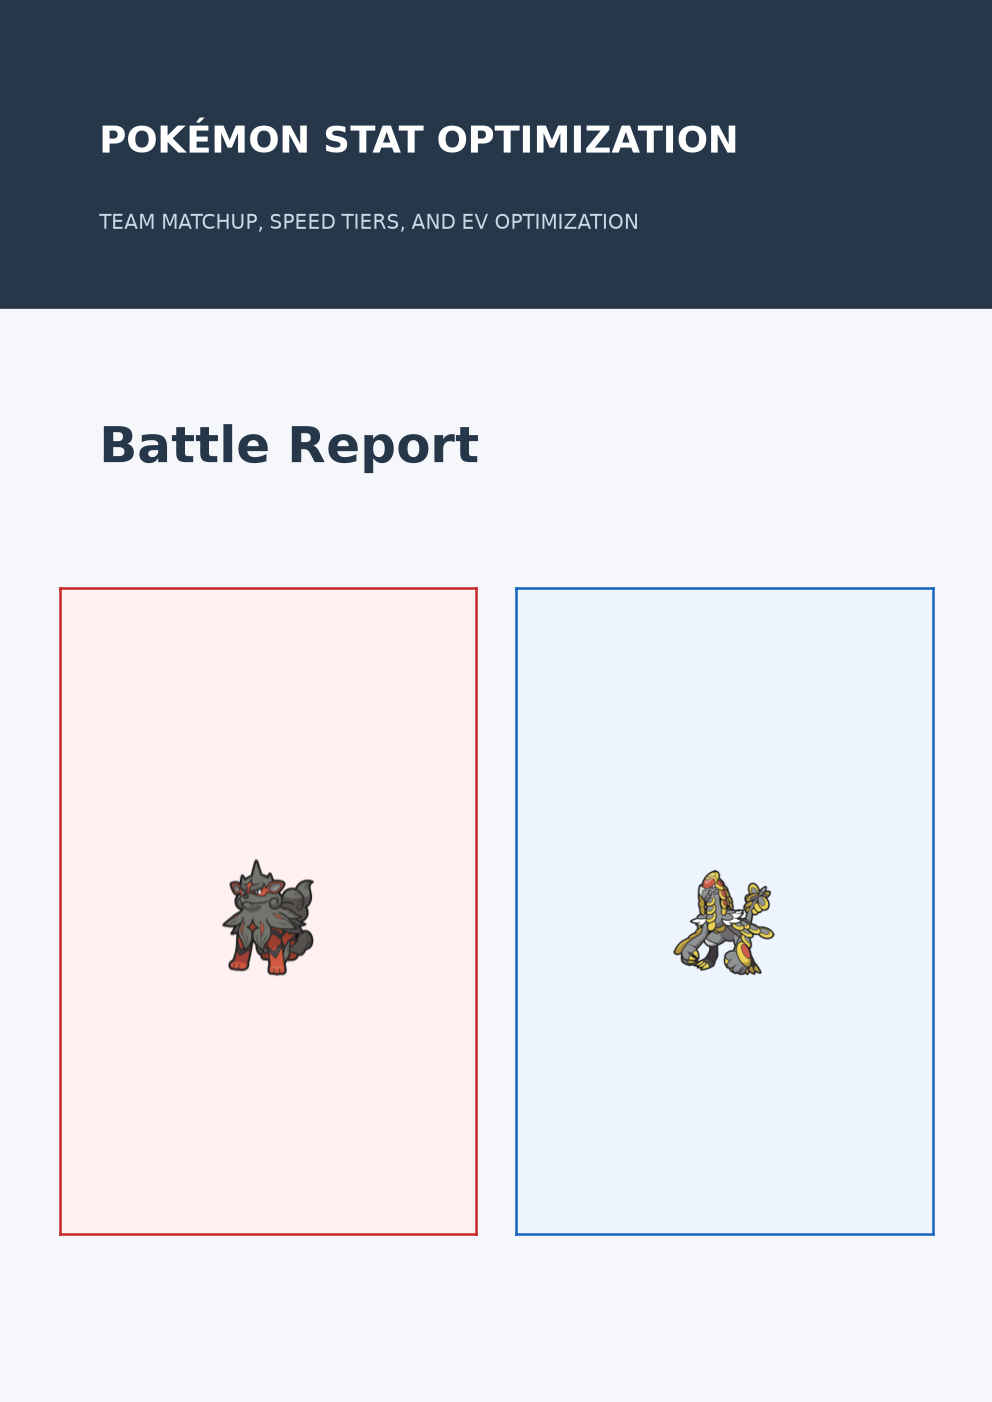

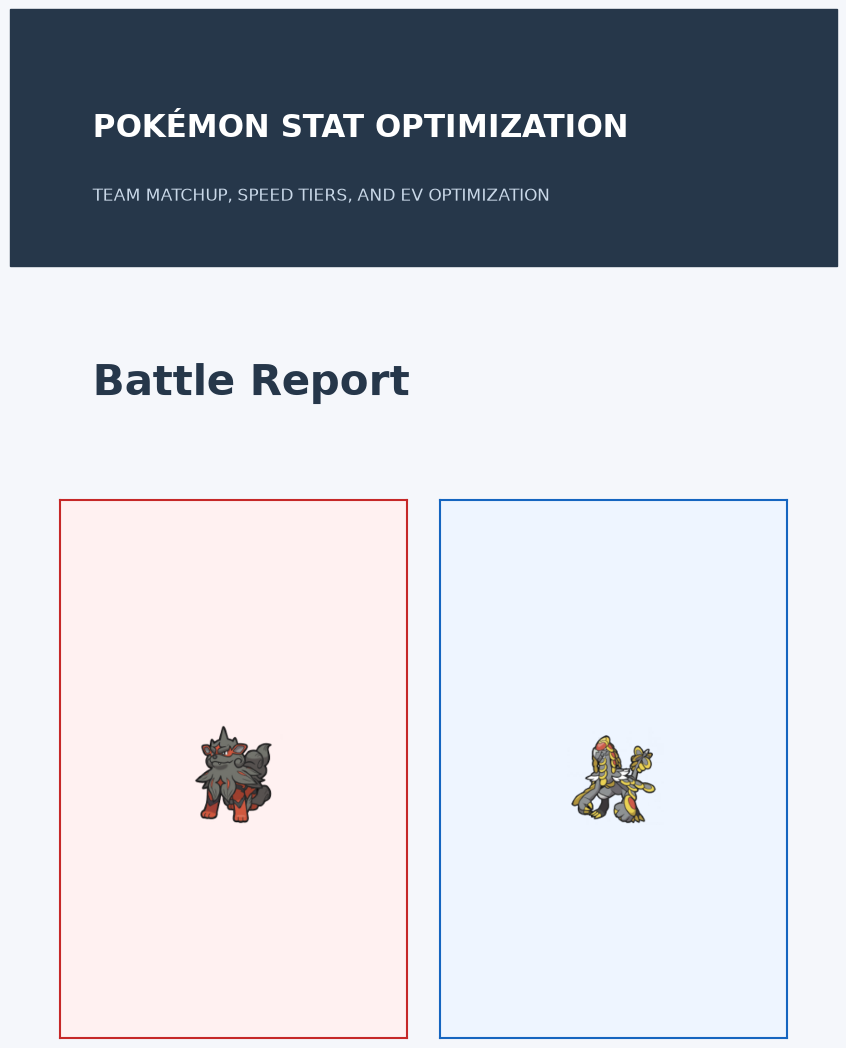

In [34]:
title_fig = plt.figure(figsize=(8.27, 11.69), facecolor="#f5f7fb")
title_fig.add_artist(plt.Rectangle(
    (0, 0.78), 1, 0.22,
    transform=title_fig.transFigure,
    color="#26374a",
    zorder=0,
))

title_fig.text(
    0.10, 0.90,
    "POKÉMON STAT OPTIMIZATION",
    color="white",
    fontsize=22,
    weight="bold",
    va="center",
)
title_fig.text(
    0.10, 0.84,
    "TEAM MATCHUP, SPEED TIERS, AND EV OPTIMIZATION",
    color="#c9d8e8",
    fontsize=12,
    va="center",
)

title_fig.text(
    0.10, 0.67,
    "Battle Report",
    color="#26374a",
    fontsize=30,
    weight="bold",
)

def add_team_sprites(ax, roster, heading, heading_color, box_color):
    ax.set_facecolor(box_color)
    ax.set_xticks([])
    ax.set_yticks([])
    ax.tick_params(left=False, bottom=False)

    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_color(heading_color)
        spine.set_linewidth(1.5)

    columns = min(3, len(roster))
    rows = (len(roster) + columns - 1) // columns

    for index, pokemon in enumerate(roster):
        row, column = divmod(index, columns)
        x = (column + 0.5) / columns
        y = 0.88 - (row + 0.5) * 0.78 / rows

        sprite_image = plt.imread(sprite_path_for(pokemon["name"]))
        sprite = OffsetImage(sprite_image, zoom=0.6)
        box = AnnotationBbox(
            sprite,
            (x, y),
            xycoords=ax.transAxes,
            frameon=False,
        )
        ax.add_artist(box)

attacker_ax = title_fig.add_axes([0.06, 0.12, 0.42, 0.46])
defender_ax = title_fig.add_axes([0.52, 0.12, 0.42, 0.46])

add_team_sprites(attacker_ax, attackers, "ATTACKERS", "#c62828", "#fff1f1")
add_team_sprites(defender_ax, defenders, "DEFENDERS", "#1565c0", "#eef5ff")


report_figures.insert(0, title_fig)
from IPython.display import Image as NotebookImage, display

preview = BytesIO()
title_fig.savefig(preview, format="png", dpi=120)  # no bbox_inches="tight"
display(NotebookImage(data=preview.getvalue()))

In [35]:
speed_tiers = [
    {
        "side": side,
        "name": pokemon["name"],
        "speed": pokemon["species"]["baseStats"]["spe"],
    }
    for side, pokemon_list in [
        ("Attacker", a_pokemon_raw),
        ("Defender", d_pokemon_raw),
    ]
    for pokemon in pokemon_list
]

speed_tiers.sort(key=lambda pokemon: pokemon["speed"], reverse=True)

print("Speed Tiers (fastest to slowest):")
for pokemon in speed_tiers:
    print(f'{pokemon["speed"]:>3}  {pokemon["name"]} ({pokemon["side"]})')

#make a nice display for the pdf for speed tiers


Speed Tiers (fastest to slowest):
 90  Arcanine-Hisui (Attacker)
 85  Kommo-o (Defender)


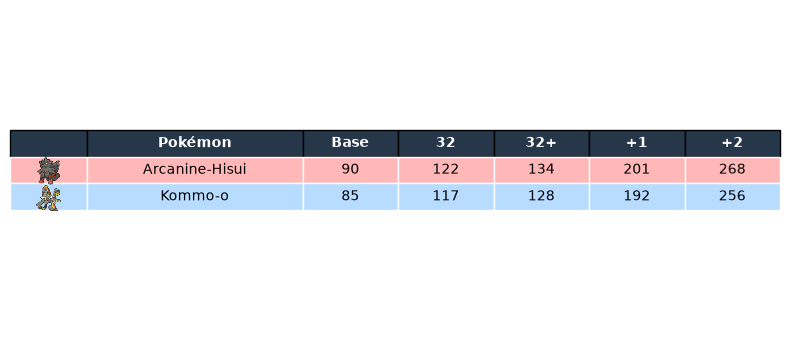

In [36]:
speed_rows = []

for pokemon in speed_tiers:
    base_speed = pokemon["speed"]
    evs32 = base_speed + 32
    evs32p = np.floor(evs32 * 1.1)
    p1 = np.floor(evs32p*1.5)
    p2 = evs32p*2

    speed_rows.append({
        "Pokémon": pokemon["name"],
        "Side": pokemon["side"],
        "Base": base_speed,
        "32": int(evs32),
        "32+": int(evs32p),
        "+1": int(p1),
        "+2": int(p2),
    })

speed_df = (
    pd.DataFrame(speed_rows)
    .sort_values("Base", ascending=False)
    .reset_index(drop=True)
)

display_df = speed_df.drop(columns="Side").copy()
display_df.insert(0, "", "")

sprite_width = 0.10
name_width = 0.28
other_width = (1 - sprite_width - name_width) / (len(display_df.columns) - 2)
col_widths = [sprite_width, name_width] + [other_width] * (len(display_df.columns) - 2)

fig, ax = plt.subplots(figsize=(8, max(3.5, len(speed_df) * 0.38 + 1.5)))
ax.axis("off")

table = ax.table(
    cellText=display_df.values,
    colLabels=display_df.columns,
    cellLoc="center",
    colLoc="center",
    colWidths=col_widths,
    loc="center",
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.35)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#26374a")
        cell.set_text_props(color="white", weight="bold")
    else:
        side = speed_df.iloc[row - 1]["Side"]
        cell.set_facecolor("#ffb7b7" if side == "Attacker" else "#b7dcff")
        cell.set_edgecolor("white")

fig.tight_layout()
fig.canvas.draw()

# Overlay each Pokémon sprite in the first (Sprite) column
for table_row, name in enumerate(speed_df["Pokémon"], start=1):
    cell = table[(table_row, 0)]
    image = plt.imread(sprite_path_for(name))
    icon = OffsetImage(image, zoom=0.18)

    x, y = cell.get_xy()
    sprite = AnnotationBbox(
        icon,
        (x + cell.get_width() / 2, y + cell.get_height() / 2),
        xycoords=ax.transAxes,
        frameon=False,
        box_alignment=(0.5, 0.5),
    )
    ax.add_artist(sprite)

report_figures.append(fig)
plt.show()

In [37]:
damaging_moves = matchup_df[matchup_df["category"] != "Status"]

best_attacks_df = damaging_moves.loc[
    damaging_moves.groupby(["attacker", "defender"])["maxDamage"].idxmax()
].reset_index(drop=True)

attacker_stats = best_attacks_df["attackerStats"].apply(pd.Series)
attacker_stats = attacker_stats.add_prefix("attacker_")

defender_stats = best_attacks_df["defenderStats"].apply(pd.Series)
defender_stats = defender_stats.add_prefix("defender_")

best_attacks_df = pd.concat(
    [best_attacks_df.drop(columns="attackerStats"), attacker_stats],
    axis=1,
)

best_attacks_df = pd.concat(
    [best_attacks_df.drop(columns="defenderStats"), defender_stats],
    axis=1,
)

best_attacks_df['max_damage_percent'] = best_attacks_df['maxDamage'] / best_attacks_df['defender_hp'] * 100
best_attacks_df['min_damage_percent'] = best_attacks_df['minDamage'] / best_attacks_df['defender_hp'] * 100


best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attacker_hp,attacker_atk,...,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent,min_damage_percent
0,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[46, 47, 48, 48, 48, 49, 50, 51, 51, 51, 52, 5...",55,46,32 Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 ...,172,167,...,100,156,150,117,153,163,125,134,36.666667,30.666667


In [38]:
forward_best_attacks_df = best_attacks_df.copy()
forward_best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attacker_hp,attacker_atk,...,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent,min_damage_percent
0,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[46, 47, 48, 48, 48, 49, 50, 51, 51, 51, 52, 5...",55,46,32 Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 ...,172,167,...,100,156,150,117,153,163,125,134,36.666667,30.666667


In [39]:
reverse_matchup_requests = [
    {
        "attacker": {key: value for key, value in opponent.items() if key != "moves"},
        "defender": {key: value for key, value in your_pokemon.items() if key != "moves"},
        "move": move,
        "field": {"gameType": "Doubles"},
    }
    for your_pokemon in attackers
    for opponent in defenders
    for move in opponent["moves"]
]

for request in reverse_matchup_requests:
    participants = {request["attacker"]["name"], request["defender"]["name"]}
    field = request["field"]
    if "Indeedee-F" in participants or "Mr. Rime" in participants:
        field["terrain"] = "Psychic"
    if "Froslass-Mega" in participants:
        field["weather"] = "Snow"
    elif "Pelipper" in participants:
        field["weather"] = "Rain"

try:
    reverse_result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": reverse_matchup_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

reverse_matchup_df = pd.DataFrame(json.loads(reverse_result.stdout))
reverse_damaging_moves = reverse_matchup_df[
    reverse_matchup_df["category"] != "Status"
]
reverse_best_attacks_df = reverse_damaging_moves.loc[
    reverse_damaging_moves.groupby(["attacker", "defender"])["maxDamage"].idxmax()
].reset_index(drop=True)

reverse_defender_stats = reverse_best_attacks_df["defenderStats"].apply(pd.Series)
reverse_best_attacks_df = pd.concat(
    [reverse_best_attacks_df.drop(columns="defenderStats"),
     reverse_defender_stats.add_prefix("defender_")],
    axis=1,
)
reverse_best_attacks_df["min_damage_percent"] = (
    reverse_best_attacks_df["minDamage"] / reverse_best_attacks_df["defender_hp"] * 100
)
reverse_best_attacks_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attackerStats,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
0,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[150, 150, 152, 152, 156, 158, 158, 162, 162, ...",176,150,29+ SpA Kommo-o Aura Sphere vs. 2 HP / 0 SpD A...,"{'hp': 150, 'atk': 117, 'def': 153, 'spa': 163...",172,167,100,103,100,156,87.209302


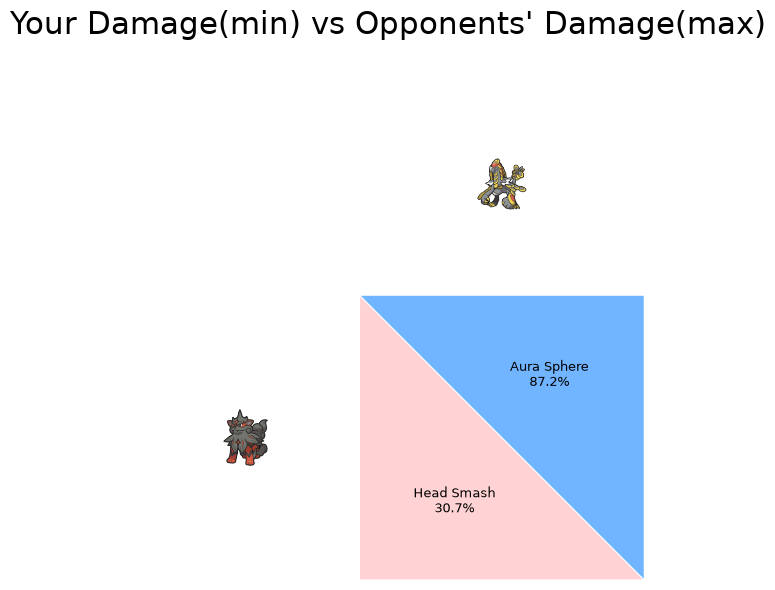

In [40]:
def add_sprite(ax, name, x, y, zoom=0.35):
    image = plt.imread(sprite_path_for(name))
    icon = OffsetImage(image, zoom=zoom)
    box = AnnotationBbox(
        icon,
        (x, y),
        frameon=False,
        annotation_clip=False,
    )
    ax.add_artist(box)

outgoing_damage = forward_best_attacks_df.pivot(
    index="attacker", columns="defender", values="min_damage_percent"
)
outgoing_moves = forward_best_attacks_df.pivot(
    index="attacker", columns="defender", values="move"
)
incoming_damage = reverse_best_attacks_df.pivot(
    index="defender", columns="attacker", values="min_damage_percent"
)
incoming_moves = reverse_best_attacks_df.pivot(
    index="defender", columns="attacker", values="move"
)

your_names = outgoing_damage.index
opponent_names = outgoing_damage.columns
incoming_damage = incoming_damage.reindex(index=your_names, columns=opponent_names)
incoming_moves = incoming_moves.reindex(index=your_names, columns=opponent_names)

norm = Normalize(vmin=0, vmax=100)
fig, ax = plt.subplots(
    figsize=(max(10, 2.4 * len(opponent_names)), max(6, 1.5 * len(your_names)))
)
triangles = []
facecolors = []

for row, your_name in enumerate(your_names):
    for col, opponent_name in enumerate(opponent_names):
        outgoing = outgoing_damage.loc[your_name, opponent_name]
        incoming = incoming_damage.loc[your_name, opponent_name]

        if pd.notna(outgoing):
            triangles.append([(col, row + 1), (col + 1, row + 1), (col, row)])
            facecolors.append(cmap_red(norm(outgoing)))
            ax.text(
                col + 1 / 3,
                row + 2 / 3,
                f"{outgoing_moves.loc[your_name, opponent_name]}\n{outgoing:.1f}%",
                ha="center",
                va="top",
                fontsize=9,
                #fontweight="bold",
            )

        if pd.notna(incoming):
            triangles.append([(col + 1, row), (col + 1, row + 1), (col, row)])
            facecolors.append(cmap_blue(norm(incoming)))
            ax.text(
                col + 2 / 3,
                row + 1 / 3,
                f"{incoming_moves.loc[your_name, opponent_name]}\n{incoming:.1f}%",
                ha="center",
                va="bottom",
                fontsize=9,
                #fontweight="bold",
            )

ax.add_collection(
    PolyCollection(triangles, facecolors=facecolors, edgecolors="white", linewidths=0.8)
)
ax.set_xlim(0, len(opponent_names))
ax.set_ylim(len(your_names), 0)
ax.set_aspect("equal")

ax.set_xlim(-0.8, len(opponent_names))
ax.set_ylim(len(your_names), -0.8)

ax.set_xticks([i + 0.5 for i in range(len(opponent_names))], labels=[])
ax.set_yticks([i + 0.5 for i in range(len(your_names))], labels=[])
ax.tick_params(length=0)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["bottom"].set_visible(False)
ax.spines["left"].set_visible(False)

for col, name in enumerate(opponent_names):
    add_sprite(ax, name, col + 0.5, -0.4)

for row, name in enumerate(your_names):
    add_sprite(ax, name, -0.4, row + 0.5)

# ax.set_xticks([i + 0.5 for i in range(len(opponent_names))], labels=opponent_names)
# ax.set_yticks([i + 0.5 for i in range(len(your_names))], labels=your_names)
ax.xaxis.tick_top()
ax.xaxis.set_label_position("top")
ax.set_title("Your Damage(min) vs Opponents' Damage(max)", pad=24, fontdict={"fontsize": 22})
# fig.colorbar(
#     ScalarMappable(norm=norm, cmap=cmap_red),
#     ax=ax,
#     fraction=0.025,
#     pad=0.04,
#     label="You -> Opponent damage (% of opponent HP)",
# )
# fig.colorbar(
#     ScalarMappable(norm=norm, cmap=cmap_blue),
#     ax=ax,
#     fraction=0.025,
#     pad=0.10,
#     label="Opponent -> You damage (% of your HP)",
# )
plt.tight_layout()
report_figures.append(fig)
#fig.savefig("matchup_heatmap.png", dpi=150, bbox_inches="tight", pad_inches=0)
plt.show()

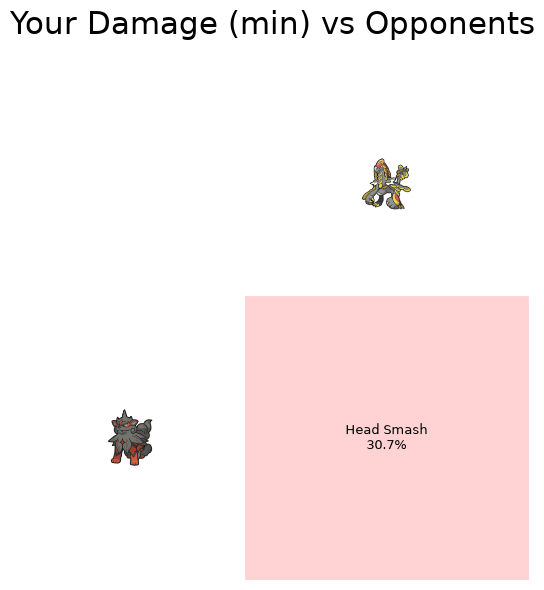

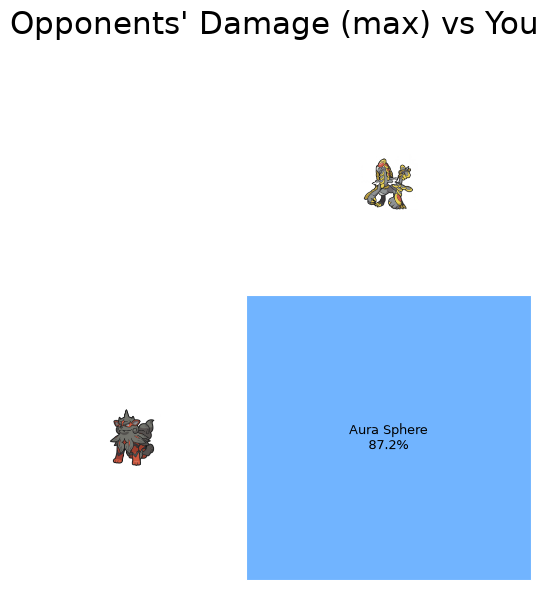

In [41]:
norm = Normalize(vmin=0, vmax=100)

def make_damage_heatmap(damage, moves, title, cmap):
    fig, ax = plt.subplots(
        figsize=(max(10, 2.4 * len(opponent_names)),
                 max(6, 1.5 * len(your_names)))
    )

    cells = []
    colors = []

    for row, your_name in enumerate(your_names):
        for col, opponent_name in enumerate(opponent_names):
            value = damage.loc[your_name, opponent_name]

            if pd.isna(value):
                continue

            cells.append([
                (col, row),
                (col + 1, row),
                (col + 1, row + 1),
                (col, row + 1),
            ])
            colors.append(cmap(norm(value)))

            ax.text(
                col + 0.5,
                row + 0.5,
                f"{moves.loc[your_name, opponent_name]}\n{value:.1f}%",
                ha="center",
                va="center",
                fontsize=9,
            )

    ax.add_collection(
        PolyCollection(cells, facecolors=colors, edgecolors="white", linewidths=0.8)
    )

    ax.set_xlim(-0.8, len(opponent_names))
    ax.set_ylim(len(your_names), -0.8)
    ax.set_aspect("equal")

    ax.set_xticks([i + 0.5 for i in range(len(opponent_names))], labels=[])
    ax.set_yticks([i + 0.5 for i in range(len(your_names))], labels=[])
    ax.tick_params(length=0)

    for spine in ax.spines.values():
        spine.set_visible(False)

    for col, name in enumerate(opponent_names):
        add_sprite(ax, name, col + 0.5, -0.4)

    for row, name in enumerate(your_names):
        add_sprite(ax, name, -0.4, row + 0.5)

    ax.xaxis.tick_top()
    ax.set_title(title, pad=24, fontdict={"fontsize": 22})

    plt.tight_layout()
    report_figures.append(fig)
    plt.show()


make_damage_heatmap(
    outgoing_damage,
    outgoing_moves,
    "Your Damage (min) vs Opponents",
    cmap_red,
)

make_damage_heatmap(
    incoming_damage,
    incoming_moves,
    "Opponents' Damage (max) vs You",
    cmap_blue,
)

In [42]:
new_requests = []

super_bulk_flag = False

for i in range(0, 33):
    #edit matchup requests to make a new request with attack evs being 0-32
    for request in matchup_requests:
        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Adamant"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)
        
        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Modest"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)

        new_request = deepcopy(request)
        new_request["attacker"]["evs"]["atk"] = i
        new_request["attacker"]["evs"]["spa"] = i
        new_request["attacker"]["nature"] = "Serious"
        if super_bulk_flag:
            new_request["defender"]["evs"]["hp"] = 32
            new_request["defender"]["evs"]["def"] = 32
            new_request["defender"]["evs"]["spd"] = 32
        new_requests.append(new_request)

In [43]:
try:
    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": new_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

new_results = json.loads(result.stdout)

In [44]:
#remove new_results that deal 0 damage

for result, request in zip(new_results, new_requests):
    attacker = request["attacker"]
    result["attack_evs"] = attacker["evs"].get("atk", 0)
    result["special_attack_evs"] = attacker["evs"].get("spa", 0)
    result["nature"] = attacker.get("nature", "Serious")

new_results = [result for result in new_results if result["damage"] != 0]
new_results_df = pd.DataFrame(new_results)

attacker_stats = new_results_df["attackerStats"].apply(pd.Series)
attacker_stats = attacker_stats.add_prefix("attacker_")

defender_stats = new_results_df["defenderStats"].apply(pd.Series)
defender_stats = defender_stats.add_prefix("defender_")

new_results_df = pd.concat(
    [new_results_df.drop(columns="attackerStats"), attacker_stats],
    axis=1,
)

new_results_df = pd.concat(
    [new_results_df.drop(columns="defenderStats"), defender_stats],
    axis=1,
)

new_results_df['min_damage_percent'] = new_results_df['minDamage'] / new_results_df['defender_hp'] * 100
new_results_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attack_evs,special_attack_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
0,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[41, 41, 42, 42, 42, 43, 44, 44, 45, 45, 45, 4...",48,41,0+ Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 ...,0,0,...,103,100,142,150,117,153,163,125,134,27.333333
1,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[33, 34, 34, 35, 36, 36, 36, 36, 37, 37, 38, 3...",40,33,0- Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 ...,0,0,...,126,100,142,150,117,153,163,125,134,22.000000
2,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[38, 38, 39, 39, 39, 40, 40, 41, 41, 42, 42, 4...",45,38,0 Atk Arcanine-Hisui Head Smash vs. 0 HP / 8 D...,0,0,...,115,100,142,150,117,153,163,125,134,25.333333
3,Arcanine-Hisui,Kommo-o,Flare Blitz,Physical,"[33, 33, 34, 34, 35, 35, 36, 36, 36, 36, 37, 3...",39,33,0+ Atk Arcanine-Hisui Flare Blitz vs. 0 HP / 8...,0,0,...,103,100,142,150,117,153,163,125,134,22.000000
4,Arcanine-Hisui,Kommo-o,Flare Blitz,Physical,"[27, 27, 27, 27, 28, 28, 29, 29, 29, 30, 30, 3...",32,27,0- Atk Arcanine-Hisui Flare Blitz vs. 0 HP / 8...,0,0,...,126,100,142,150,117,153,163,125,134,18.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
292,Arcanine-Hisui,Kommo-o,Flare Blitz,Physical,"[33, 33, 34, 34, 35, 35, 36, 36, 36, 36, 37, 3...",39,33,32- Atk Arcanine-Hisui Flare Blitz vs. 0 HP / ...,32,32,...,161,100,142,150,117,153,163,125,134,22.000000
293,Arcanine-Hisui,Kommo-o,Flare Blitz,Physical,"[37, 37, 38, 38, 39, 39, 39, 40, 40, 41, 42, 4...",44,37,32 Atk Arcanine-Hisui Flare Blitz vs. 0 HP / 8...,32,32,...,147,100,142,150,117,153,163,125,134,24.666667
294,Arcanine-Hisui,Kommo-o,Extreme Speed,Physical,"[37, 37, 38, 38, 39, 39, 40, 40, 40, 41, 41, 4...",44,37,32+ Atk Arcanine-Hisui Extreme Speed vs. 0 HP ...,32,32,...,132,100,142,150,117,153,163,125,134,24.666667
295,Arcanine-Hisui,Kommo-o,Extreme Speed,Physical,"[30, 30, 31, 31, 32, 32, 32, 33, 33, 33, 34, 3...",36,30,32- Atk Arcanine-Hisui Extreme Speed vs. 0 HP ...,32,32,...,161,100,142,150,117,153,163,125,134,20.000000


In [45]:
#for each attack per pokemon per defender, find the move that deals the minimum damage percent that is closest to 100 without going under
def choose_best_index(group):
    at_least_100 = group[group["min_damage_percent"] >= 100]
    candidates = at_least_100 if not at_least_100.empty else group
    return (candidates["min_damage_percent"] - 100).abs().idxmin()

best_moves = new_results_df.loc[
    new_results_df.groupby(["attacker", "defender"], group_keys=False)
    .apply(choose_best_index)
]

In [46]:
best_moves

,attacker,defender,move,category,damage,maxDamage,minDamage,description,attack_evs,special_attack_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,min_damage_percent
270,Arcanine-Hisui,Kommo-o,Head Smash,Physical,"[51, 51, 51, 52, 53, 54, 54, 54, 55, 56, 57, 5...",60,51,30+ Atk Arcanine-Hisui Head Smash vs. 0 HP / 8...,30,30,...,130,100,142,150,117,153,163,125,134,34.0


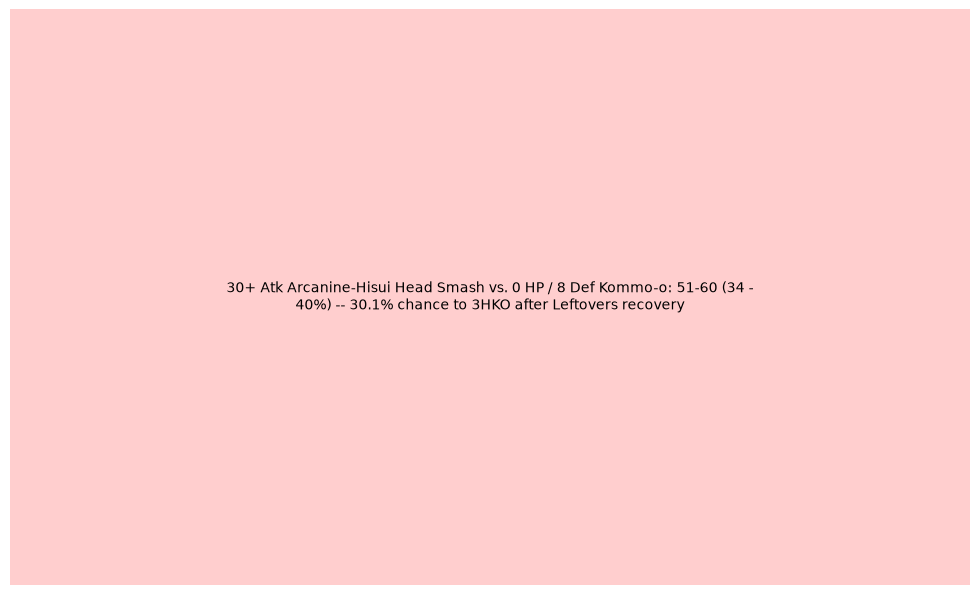

In [47]:
#for each attacker in best moves, create a simple table/heatmap showing the minimum damage percent against each defender

sprites_flag = False
image_dir = Path("heatmap_images")
image_dir.mkdir(exist_ok=True)

attacker_figs = {}

for attacker, group in best_moves.groupby("attacker"):
    group["wrapped_description"] = group["description"].apply(
        lambda text: textwrap.fill(str(text), width=75)
    )

    pivot_table = group.pivot(
        index="defender",
        columns="attacker",
        values="min_damage_percent"
    )
    description_table = group.pivot(
        index="defender",
        columns="attacker",
        values="wrapped_description",
    ).reindex(index=pivot_table.index, columns=pivot_table.columns)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(
        pivot_table,
        annot=description_table,
        fmt="",
        cmap=cmap_red,
        # cbar_kws={'label': 'Min Damage %'},
        vmin=0,
        vmax=100,
        annot_kws={"color": "black"},
        )

    #removing extra labels and colour bar
    ax.set_yticklabels([])
    ax.set_ylabel("")
    ax.tick_params(axis="y", length=0)
    ax.set_xticklabels([])
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=0)
    ax.collections[0].colorbar.remove()


    if sprites_flag:
        # Put each defender's sprite next to its heatmap row
        for row, defender in enumerate(pivot_table.index):
            filename = defender.lower().replace(" ", "-") + ".png"
            sprite_path = sprite_dir / filename

            if sprite_path.exists():
                image = mpimg.imread(sprite_path)
                sprite = OffsetImage(image, zoom=0.35)
                box = AnnotationBbox(
                    sprite,
                    (-0.05, row + 0.5),
                    xycoords=ax.transData,
                    frameon=False,
                    box_alignment=(0.5, 0.5),
                )
                ax.add_artist(box)

    image_path = image_dir / f"{attacker.lower().replace(' ', '-')}.png"
    fig.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.02)
    #report_figures.append(fig)
    #fig.savefig(image_path, dpi=150, bbox_inches="tight", pad_inches=0)
    attacker_figs[attacker] = fig
    plt.show()

In [48]:
new_requests = []

super_strength_flag = False
only_neutral_nature = True

for i in range(0, 33):
    for j in range(0, 33):
        #edit matchup requests to make a new request with attack evs being 0-32
        for request in reverse_matchup_requests:
            if not only_neutral_nature:
                new_request = deepcopy(request)
                new_request["defender"]["evs"]["hp"] = i
                new_request["defender"]["evs"]["def"] = j
                new_request["defender"]["evs"]["spd"] = j
                new_request["defender"]["nature"] = "Lax"
                if super_strength_flag:
                    new_request["defender"]["evs"]["hp"] = 32
                    new_request["defender"]["evs"]["def"] = 32
                    new_request["defender"]["evs"]["spd"] = 32
                new_requests.append(new_request)
                
                new_request = deepcopy(request)
                new_request["defender"]["evs"]["hp"] = i
                new_request["defender"]["evs"]["def"] = j
                new_request["defender"]["evs"]["spd"] = j
                new_request["defender"]["nature"] = "Gentle"
                if super_strength_flag:
                    new_request["defender"]["evs"]["hp"] = 32
                    new_request["defender"]["evs"]["def"] = 32
                    new_request["defender"]["evs"]["spd"] = 32
                new_requests.append(new_request)

            new_request = deepcopy(request)
            new_request["defender"]["evs"]["hp"] = i
            new_request["defender"]["evs"]["def"] = j
            new_request["defender"]["evs"]["spd"] = j
            new_request["defender"]["nature"] = "Serious"
            if super_strength_flag:
                new_request["defender"]["evs"]["hp"] = 32
                new_request["defender"]["evs"]["def"] = 32
                new_request["defender"]["evs"]["spd"] = 32
            new_requests.append(new_request)

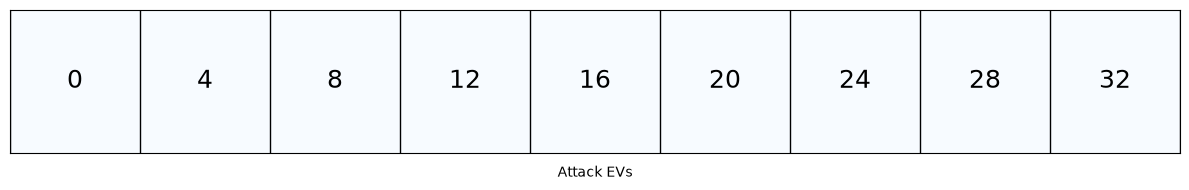

In [49]:
atk_evs = np.arange(0, 33, 4)

fig, ax = plt.subplots(figsize=(12, 2))

ax.imshow(np.zeros((1, len(atk_evs))), cmap="Blues", aspect="auto")

for col, attack in enumerate(atk_evs):
    ax.text(col, 0, str(attack),
            ha="center", va="center", fontsize=18)

# Divider lines between cells
ax.set_xticks(np.arange(-0.5, len(atk_evs), 1), minor=True)
ax.grid(which="minor", color="black", linewidth=1)

ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_xlabel("Attack EVs")

plt.tight_layout()
plt.show()

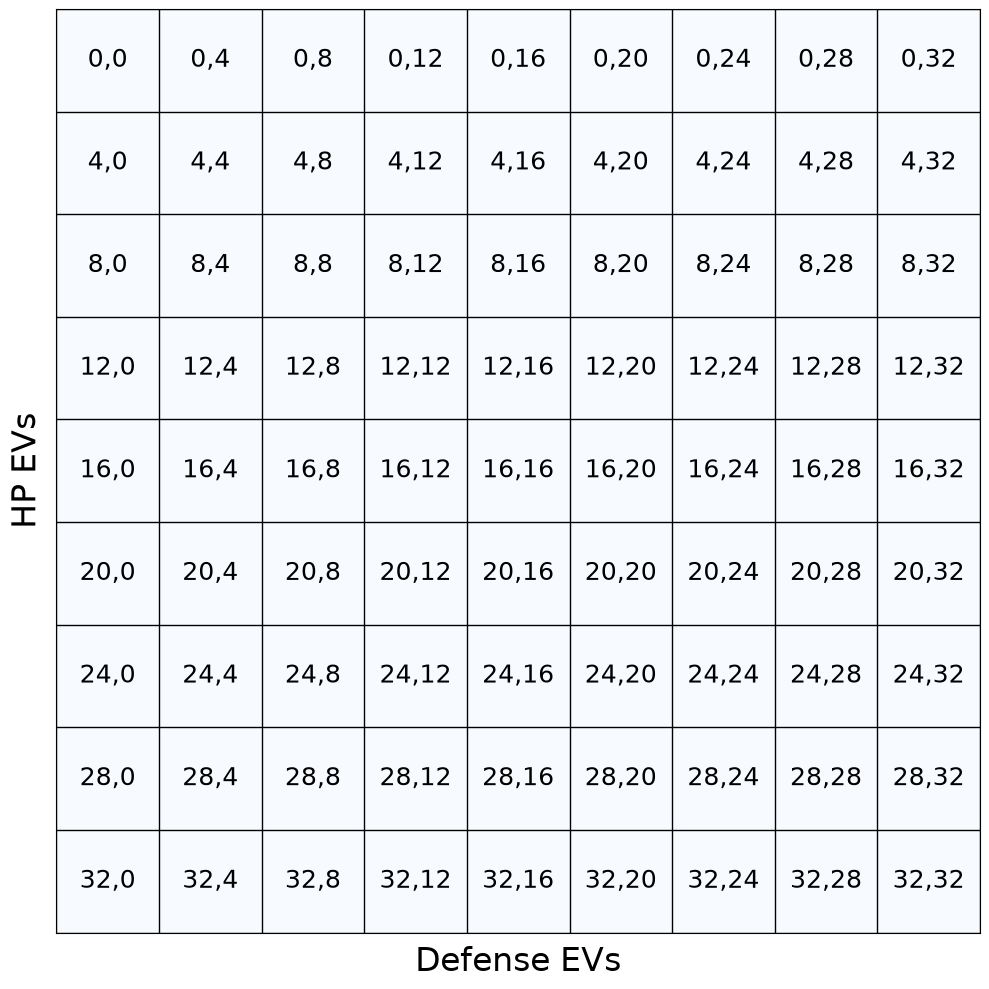

In [50]:
hp_evs = np.arange(0, 33, 4)
def_evs = np.arange(0, 33, 4)

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(np.zeros((len(hp_evs), len(def_evs))), cmap="Blues")

for row, hp in enumerate(hp_evs):
    for col, defense in enumerate(def_evs):
        ax.text(col, row, f"{hp},{defense}",
            ha="center", va="center", fontsize=18)

# Divider lines between cells
ax.set_xticks(np.arange(-0.5, len(def_evs), 1), minor=True)
ax.set_yticks(np.arange(-0.5, len(hp_evs), 1), minor=True)
ax.grid(which="minor", color="black", linewidth=1)

# Hide side numbers while keeping the grid
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(which="minor", bottom=False, left=False)

ax.set_xlabel("Defense EVs", fontsize=24)
ax.set_ylabel("HP EVs", fontsize=24)

plt.tight_layout()
plt.show()

In [51]:
try:
    result = subprocess.run(
        ["node", "damage.js"],
        input=json.dumps({"generation": 0, "matchups": new_requests}),
        cwd=project_dir,
        check=True,
        capture_output=True,
        text=True,
    )
except subprocess.CalledProcessError as error:
    print(error.stderr)
    raise

new_results = json.loads(result.stdout)

In [52]:
#remove new_results that deal 0 damage

for result, request in zip(new_results, new_requests):
    defender = request["defender"]
    result["hp_evs"] = defender["evs"].get("hp", 0)
    result["defense_evs"] = defender["evs"].get("def", 0)
    result["special_defense_evs"] = defender["evs"].get("spd", 0)
    result["total_evs"] = result["hp_evs"] + result["defense_evs"]
    result["nature"] = defender.get("nature", "Serious")


new_results = [result for result in new_results if result["damage"] != 0]
new_results_df = pd.DataFrame(new_results)

attacker_stats = new_results_df["attackerStats"].apply(pd.Series)
attacker_stats = attacker_stats.add_prefix("attacker_")

defender_stats = new_results_df["defenderStats"].apply(pd.Series)
defender_stats = defender_stats.add_prefix("defender_")

new_results_df = pd.concat(
    [new_results_df.drop(columns="attackerStats"), attacker_stats],
    axis=1,
)

new_results_df = pd.concat(
    [new_results_df.drop(columns="defenderStats"), defender_stats],
    axis=1,
)

new_results_df['max_damage_percent'] = new_results_df['maxDamage'] / new_results_df['defender_hp'] * 100
new_results_df

,attacker,defender,move,category,damage,maxDamage,minDamage,description,hp_evs,defense_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent
0,Kommo-o,Arcanine-Hisui,Clanging Scales,Special,"[76, 76, 78, 78, 79, 81, 81, 82, 82, 84, 85, 8...",90,76,29+ SpA Kommo-o Clanging Scales vs. 0 HP / 0 S...,0,0,...,163,125,134,170,167,100,115,100,142,52.941176
1,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[150, 150, 152, 152, 156, 158, 158, 162, 162, ...",176,150,29+ SpA Kommo-o Aura Sphere vs. 0 HP / 0 SpD A...,0,0,...,163,125,134,170,167,100,115,100,142,103.529412
2,Kommo-o,Arcanine-Hisui,Clanging Scales,Special,"[76, 76, 78, 78, 79, 81, 81, 82, 82, 84, 85, 8...",90,76,29+ SpA Kommo-o Clanging Scales vs. 0 HP / 1 S...,0,1,...,163,125,134,170,167,101,115,101,142,52.941176
3,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[146, 146, 150, 152, 152, 156, 156, 158, 158, ...",174,146,29+ SpA Kommo-o Aura Sphere vs. 0 HP / 1 SpD A...,0,1,...,163,125,134,170,167,101,115,101,142,102.352941
4,Kommo-o,Arcanine-Hisui,Clanging Scales,Special,"[75, 75, 76, 76, 78, 79, 79, 81, 81, 82, 84, 8...",88,75,29+ SpA Kommo-o Clanging Scales vs. 0 HP / 2 S...,0,2,...,163,125,134,170,167,102,115,102,142,51.764706
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2173,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[116, 116, 120, 120, 120, 122, 122, 126, 126, ...",138,116,29+ SpA Kommo-o Aura Sphere vs. 32 HP / 30 SpD...,32,30,...,163,125,134,202,167,130,115,130,142,68.316832
2174,Kommo-o,Arcanine-Hisui,Clanging Scales,Special,"[58, 58, 60, 60, 60, 61, 61, 63, 63, 64, 64, 6...",69,58,29+ SpA Kommo-o Clanging Scales vs. 32 HP / 31...,32,31,...,163,125,134,202,167,131,115,131,142,34.158416
2175,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[114, 114, 116, 116, 120, 120, 120, 122, 122, ...",134,114,29+ SpA Kommo-o Aura Sphere vs. 32 HP / 31 SpD...,32,31,...,163,125,134,202,167,131,115,131,142,66.336634
2176,Kommo-o,Arcanine-Hisui,Clanging Scales,Special,"[58, 58, 60, 60, 60, 61, 61, 63, 63, 64, 64, 6...",69,58,29+ SpA Kommo-o Clanging Scales vs. 32 HP / 32...,32,32,...,163,125,134,202,167,132,115,132,142,34.158416


In [53]:
def choose_best_index(group):
    # Identify the move with the highest damage across the tested spreads
    strongest_move = group.loc[
        group["max_damage_percent"].idxmax(), "move"
    ]

    # Check which EV spreads survive that move
    strongest_move_rows = group[group["move"] == strongest_move]
    survivors = strongest_move_rows[
        strongest_move_rows["max_damage_percent"] < 100
    ]

    if not survivors.empty:
        neutral_survivors = survivors[survivors["nature"] == "Serious"]
        # Among spreads that survive, use the fewest total EVs
        if not neutral_survivors.empty:
            return neutral_survivors["total_evs"].idxmin()
        return survivors["total_evs"].idxmin()

    # If none survive, select the spread that reduces damage the most
    return strongest_move_rows["max_damage_percent"].idxmin()




selected_indices = (
    new_results_df.groupby(["attacker", "defender"])
    .apply(choose_best_index)
)

best_moves = new_results_df.loc[selected_indices.astype(int)]

In [54]:
best_moves

,attacker,defender,move,category,damage,maxDamage,minDamage,description,hp_evs,defense_evs,...,attacker_spa,attacker_spd,attacker_spe,defender_hp,defender_atk,defender_def,defender_spa,defender_spd,defender_spe,max_damage_percent
73,Kommo-o,Arcanine-Hisui,Aura Sphere,Special,"[144, 146, 146, 150, 150, 152, 152, 156, 158, ...",170,144,29+ SpA Kommo-o Aura Sphere vs. 1 HP / 3 SpD A...,1,3,...,163,125,134,171,167,103,115,103,142,99.415205


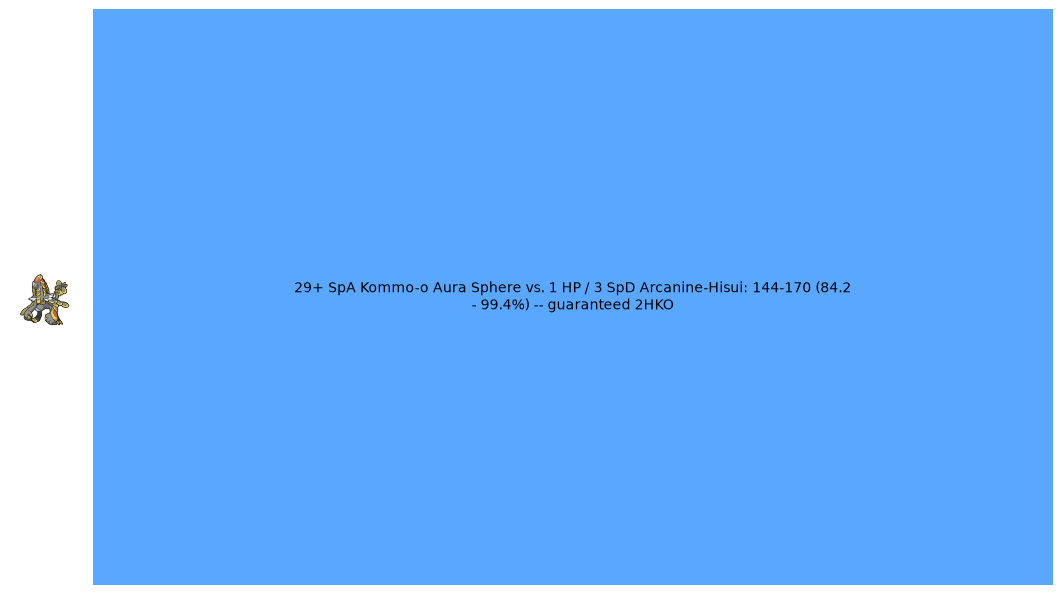

In [55]:
#for each attacker in best moves, create a simple table/heatmap showing the maximum damage percent against each defender

defender_figs = {}

for defender, group in best_moves.groupby("defender"):
    group["wrapped_description"] = group["description"].apply(
        lambda text: textwrap.fill(str(text), width=75)
    )

    pivot_table = group.pivot(
        index="attacker",
        columns="defender",
        values="max_damage_percent"
    )
    description_table = group.pivot(
        index="attacker",
        columns="defender",
        values="wrapped_description",
    ).reindex(index=pivot_table.index, columns=pivot_table.columns)
    
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.heatmap(
        pivot_table,
        annot=description_table,
        fmt="",
        cmap=cmap_blue,
        # cbar_kws={'label': 'Min Damage %'},
        vmin=0,
        vmax=100,
        annot_kws={"color": "black"},
        ax=ax,
        )

    #removing extra labels and colour bar
    ax.set_yticklabels([])
    ax.set_ylabel("")
    ax.tick_params(axis="y", length=0)
    ax.set_xticklabels([])
    ax.set_xlabel("")
    ax.tick_params(axis="x", length=0)
    ax.collections[0].colorbar.remove()
    ax.set_xlim(-0., pivot_table.shape[1])

     # Put each defender's sprite next to its heatmap row
    for row, defender_name in enumerate(pivot_table.index):
        filename = defender_name.lower().replace(" ", "-").replace(".", "") + ".png"
        filename = filename.replace("-f", "-female")
        #print(filename)
        sprite_path = sprite_dir / filename

        if sprite_path.exists():
            image = mpimg.imread(sprite_path)
            sprite = OffsetImage(image, zoom=0.35)
            box = AnnotationBbox(
                sprite,
                (-0.05, row + 0.5),
                xycoords=ax.transData,
                frameon=False,
                box_alignment=(0.5, 0.5),
                annotation_clip=False,
            )
            ax.add_artist(box)
            
    image_path = image_dir / f"{defender.lower().replace(' ', '-')}_def.png"
    fig.subplots_adjust(left=0.02, right=0.98, top=0.98, bottom=0.02)
    #report_figures.append(fig)
    #fig.savefig(image_path, dpi=150, bbox_inches="tight", pad_inches=0)
    defender_figs[defender] = fig
    plt.show()

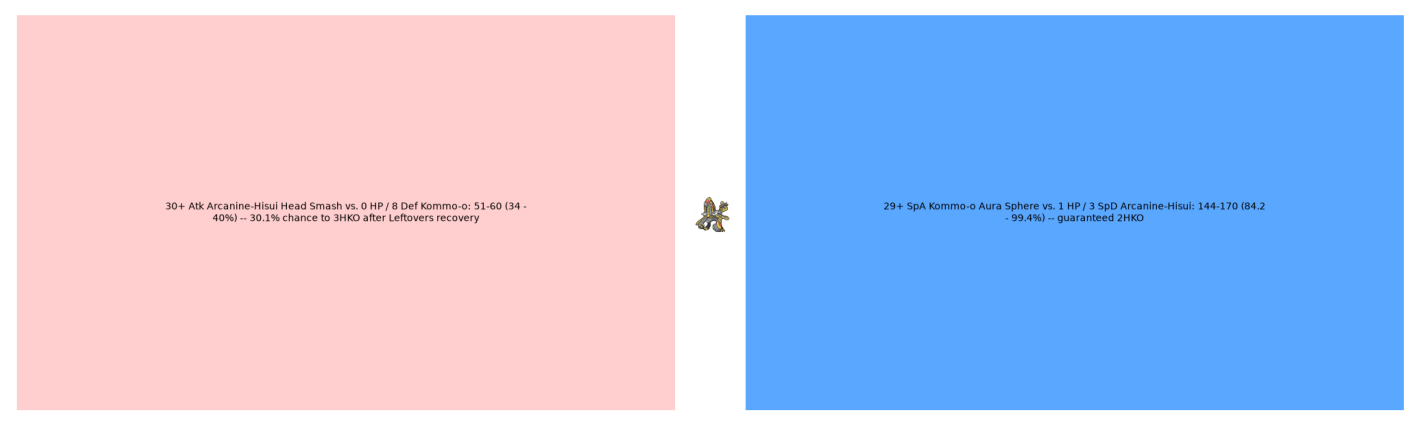

In [56]:
def figure_to_image(source_figure):
    buffer = BytesIO()
    source_figure.savefig(buffer, format="png", bbox_inches="tight")
    buffer.seek(0)
    return mpimg.imread(buffer)

merged_damage_figures = {}

for pokemon in attackers:
    pokemon_name = pokemon["name"]

    attacker_image = figure_to_image(attacker_figs[pokemon_name])
    defender_image = figure_to_image(defender_figs[pokemon_name])

    fig = plt.figure(figsize=(14, 7))

    images = [attacker_image, defender_image]
    height = 0.9  # shared image height, as a fraction of the figure
    gap = 0.00

    # Convert image aspect ratios to figure-relative widths.
    width_factors = [
        (image.shape[1] / image.shape[0])
        * (fig.get_figheight() / fig.get_figwidth())
        for image in images
    ]

    # Reduce both images equally if they would exceed the figure width.
    if height * sum(width_factors) + gap > 1:
        height = (1 - gap) / sum(width_factors)

    widths = [height * factor for factor in width_factors]
    left = (1 - sum(widths) - gap) / 2
    bottom = (1 - height) / 2

    for image, width in zip(images, widths):
        ax = fig.add_axes([left, bottom, width, height])
        ax.imshow(image, aspect="equal")
        ax.axis("off")
        left += width + gap

    merged_damage_figures[pokemon_name] = fig

In [57]:
attackers = read_showdown_team(project_dir / "attackers.txt")

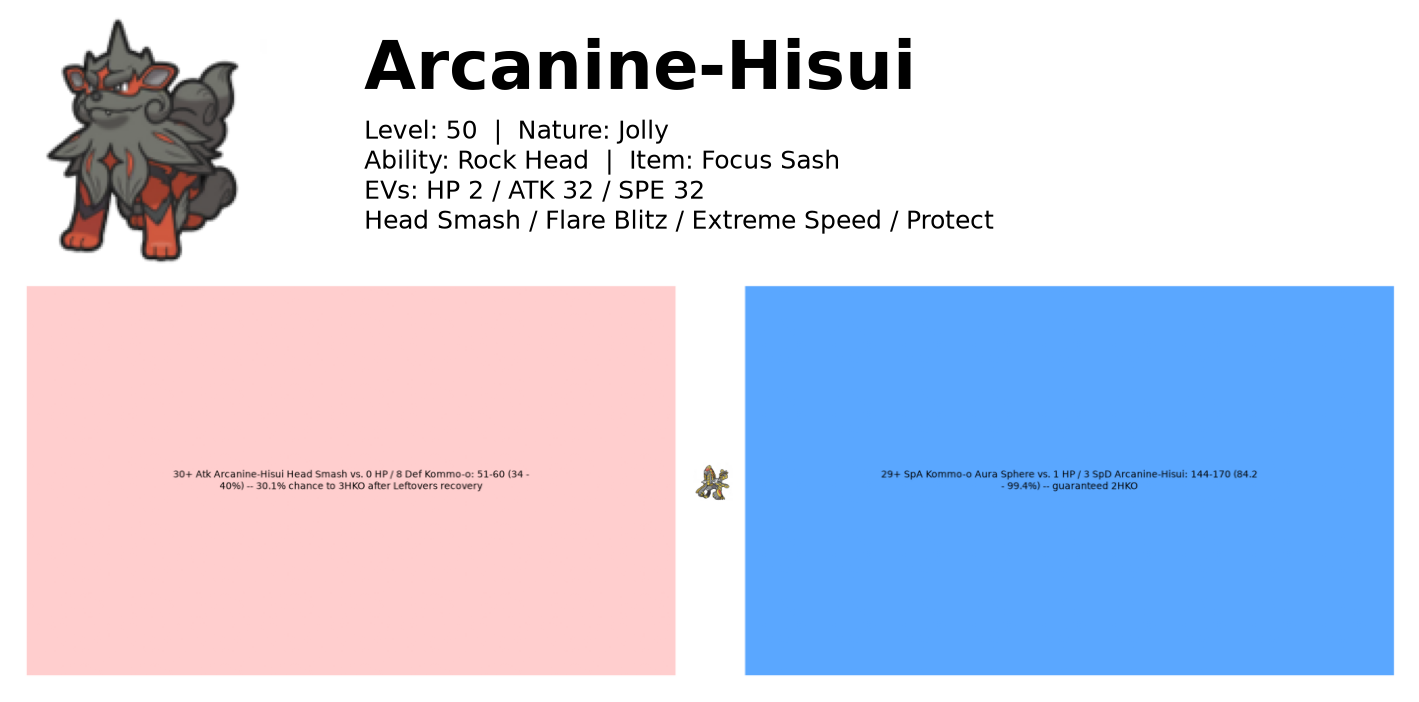

In [58]:
for attacker in attackers:
    name = attacker["name"]
    sprite_path = sprite_path_for(name)

    fig = plt.figure(figsize=(14, 8))

    gs = GridSpec(
    2, 3,
    figure=fig,
    height_ratios=[1, 5],
    width_ratios=[1, 2, 2],
    )

    # Sprite: top left
    sprite_ax = fig.add_subplot(gs[0, 0])
    sprite_ax.axis("off")

    if sprite_path.exists():
        sprite = OffsetImage(mpimg.imread(sprite_path), zoom=1.5)
        box = AnnotationBbox(
            sprite,
            (0.03, 0.97),
            xycoords="axes fraction",
            box_alignment=(0, 1),         # align sprite's top-left to that position
            frameon=False,
        )
        sprite_ax.add_artist(box)
    else:
        print(f"Sprite not found: {sprite_path}")

    # Placeholder text: top middle
    evs = attacker.get("evs", {})
    ev_text = " / ".join(
        f"{stat.upper()} {value}"
        for stat, value in evs.items()
    )

    middle_ax = fig.add_subplot(gs[0, 1])
    middle_ax.axis("off")

    details = (
    f'Level: {attacker.get("level", "—")}  |  '
    f'Nature: {attacker.get("nature", "—")}\n'
    f'Ability: {attacker.get("ability", "—")}  |  '
    f'Item: {attacker.get("item", "—")}\n'
    f'EVs: {ev_text}\n'
    f'{" / ".join(attacker.get("moves", []))}'
    )

    middle_ax.text(
        0.05, 0.8,
        attacker["name"],
        fontsize=48,
        fontweight="bold",
        va="top",
        transform=middle_ax.transAxes,
    )

    middle_ax.text(
        0.05, 0.2,
        details,
        fontsize=18,
        va="top",
        transform=middle_ax.transAxes,
    )

    # Placeholder text: top right
    right_ax = fig.add_subplot(gs[0, 2])
    right_ax.axis("off")

    right_ax.text(
        0.00, 0.2,
        " ",
        fontsize=18,
        va="top",
        transform=right_ax.transAxes,
    )


    graph_ax = fig.add_subplot(gs[1, :])
    graph_ax.imshow(figure_to_image(merged_damage_figures[name]))
    graph_ax.axis("off")

    fig.subplots_adjust(left=0, right=1, bottom=0, top=1, hspace=0.02)
    report_figures.append(fig)
    plt.show()
    plt.close(fig)

In [59]:
def read_wrapped_lines(path, width=55):
    lines = []
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        lines.extend(textwrap.wrap(line, width=width) or [""])
    return lines

attacker_lines = read_wrapped_lines("attackers.txt")
defender_lines = read_wrapped_lines("defenders.txt")

lines_per_page = 48
page_count = max(
    (len(attacker_lines) + lines_per_page - 1) // lines_per_page,
    (len(defender_lines) + lines_per_page - 1) // lines_per_page,
)

for page_num in range(page_count):
    start = page_num * lines_per_page

    fig = plt.figure(figsize=(11, 8.5))  # landscape letter
    fig.text(
        0.05, 0.95,
        "\n".join(attacker_lines[start:start + lines_per_page]),
        ha="left", va="top", family="monospace", fontsize=10,
    )
    fig.text(
        0.53, 0.95,
        "\n".join(defender_lines[start:start + lines_per_page]),
        ha="left", va="top", family="monospace", fontsize=10,
    )

    report_figures.append(fig)
    #pdf.savefig(fig)
    plt.close(fig)

In [60]:
output_pdf = Path("pokemon_report.pdf")
writer = PdfWriter()

from matplotlib.backends.backend_pdf import PdfPages

with PdfPages("pokemon_report.pdf") as pdf:
    for fig in report_figures:
        pdf.savefig(fig, bbox_inches="tight")

for fig in report_figures:
    plt.close(fig)